<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



# جلسه ۷ — تحلیل مؤلفه‌های اصلی (PCA)
### مبانی ریاضی یادگیری ماشین | بخش دوم: جبر خطی پیشرفته

**اهداف یادگیری این جلسه:**
- فهم PCA از دو دیدگاه هم‌ارز: «بیشینه کردن واریانس» و «کمینه کردن خطای تصویرسازی»
- محاسبه‌ی PCA با کد (هم از طریق مقادیر/بردارهای ویژه‌ی جلسه ۴، هم از طریق SVD جلسه ۵)
- کاهش ابعاد داده‌ی چندبعدی به ۲ بعد برای مشاهده‌ی الگوها با چشم

> 📘 **جعبه واژه‌نامه** — هر جا اصطلاح تخصصی جدیدی به‌کار می‌رود، همین‌جا با یک مثال ساده و غیرتخصصی توضیح داده می‌شود. لازم نیست از قبل این کلمات را بلد باشید.

> **پیش‌مطالعه:** فصل ۱۰ *Mathematics for Machine Learning* (PCA) — این جلسه مستقیماً جلسات ۴ و ۵ را به هم وصل می‌کند، پس یک مرور سریع آن دو جلسه هم مفید است.



<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


## 🎯 چالش واقعی این جلسه: چطور ۵۰ ویژگی را روی یک صفحه‌ی دوبعدی ببینیم؟

فرض کنید برای هر کاربر پروژه‌ی خودتان ده‌ها ویژگی جمع‌آوری کرده‌اید: سن، درآمد، تعداد بازدید، مدت‌زمان حضور در سایت، تعداد خرید، امتیاز رضایت، و... چشم انسان نمی‌تواند فضای ۵۰-بعدی را تصور کند، اما اگر بخواهیم الگوها را ببینیم (مثلاً «آیا کاربران به چند دسته‌ی طبیعی تقسیم می‌شوند؟»)، باید این داده را در ۲ یا ۳ بُعد رسم کنیم.

سؤال: چطور می‌توانیم از ۵۰ بُعد به ۲ بُعد برویم، بدون این‌که مهم‌ترین الگوهای داده را از دست بدهیم؟

شکل داده: (200, 4) → ۴ بعد را روی چشم نمی‌شود دید!
دو ستون اول را ببینیم (فقط برای کنجکاوی، این بهترین راه نیست):


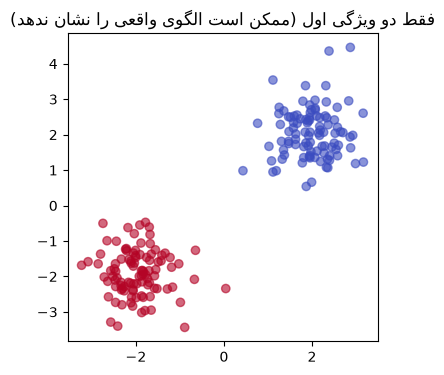

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(0)

# داده‌ی ساختگی: ۲۰۰ کاربر، ۲ گروه طبیعی، اما در فضای ۴ بعدی نمایش داده شده
# (تصور کنید این ۴ بعد نماینده‌ی ۵۰ ویژگی واقعی پروژه‌ی شماست)
group1 = torch.randn(100, 4) * 0.6 + torch.tensor([2.0, 2.0, 1.0, -1.0])
group2 = torch.randn(100, 4) * 0.6 + torch.tensor([-2.0, -2.0, -1.0, 1.0])
data = torch.cat([group1, group2], dim=0)
labels = torch.cat([torch.zeros(100), torch.ones(100)])

print("شکل داده:", tuple(data.shape), "→ ۴ بعد را روی چشم نمی‌شود دید!")
print("دو ستون اول را ببینیم (فقط برای کنجکاوی، این بهترین راه نیست):")

plt.figure(figsize=(4, 4))
plt.scatter(data[:, 0], data[:, 1], c=labels, cmap="coolwarm", alpha=0.6)
plt.title("فقط دو ویژگی اول (ممکن است الگوی واقعی را نشان ندهد)")
plt.show()


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



انتخاب «فقط دو ویژگی اول» یک تصمیم دلبخواهی است — شاید مهم‌ترین الگوی داده در ترکیبی از چند ویژگی دیگر پنهان باشد. **PCA** به‌جای انتخاب دلبخواهی، بهترین ۲ جهت (آن‌هایی که بیشترین واریانس/تنوع داده را نشان می‌دهند) را پیدا می‌کند.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۱: دو نگاه هم‌ارز به PCA

📘 **واریانس (Variance)** میزان «پراکندگی» داده حول میانگینش را اندازه می‌گیرد — هرچه داده در یک جهت بیشتر پخش شده باشد، واریانس در آن جهت بیشتر است. جهتی با واریانس بالا معمولاً جهتی است که «اطلاعات» بیشتری درباره‌ی تفاوت بین نمونه‌ها دارد.

PCA را می‌توان از دو مسیر ریاضی که در نهایت به یک جواب می‌رسند فهمید:

**نگاه اول (بیشینه‌سازی واریانس):** جهتی را پیدا کن که وقتی داده را روی آن تصویر (Project) می‌کنیم، پراکندگیِ نقاط تصویرشده بیشترین مقدار ممکن باشد.

**نگاه دوم (کمینه‌سازی خطای تصویرسازی):** جهتی را پیدا کن که وقتی داده را روی آن تصویر می‌کنیم و بعد سعی می‌کنیم داده‌ی اصلی را از روی آن تصویر بازسازی کنیم، کمترین خطای بازسازی را داشته باشیم.

این دو، ریاضیاتاً همان جواب را می‌دهند: هر دو به بردارهای ویژه‌ی **ماتریس کوواریانس** داده می‌رسند (دقیقاً همان مفهومی که در جلسه ۴ دیدیم، فقط این‌بار روی ماتریس کوواریانس اعمال می‌شود).

In [3]:
def pca(X, n_components):
    # مرحله ۱: مرکز کردن داده (میانگین هر ستون را از آن کم می‌کنیم)
    X_centered = X - X.mean(dim=0)

    # مرحله ۲: ماتریس کوواریانس
    cov = torch.cov(X_centered.T)

    # مرحله ۳: بردار/مقدار ویژه‌ی ماتریس کوواریانس (یادتان هست؟ جلسه ۴!)
    eigvals, eigvecs = torch.linalg.eigh(cov)

    # مرتب‌سازی نزولی بر اساس مقدار ویژه (بزرگ‌ترین واریانس اول)
    order = torch.argsort(eigvals, descending=True)
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # مرحله ۴: تصویر داده روی n_components بردار ویژه‌ی برتر
    components = eigvecs[:, :n_components]
    projected = X_centered @ components

    explained_variance_ratio = eigvals[:n_components] / eigvals.sum()
    return projected, explained_variance_ratio
 m
projected, evr = pca(data, n_components=2)
print("shape داده بعد از کاهش بعد:")
print(tuple(projected.shape))
print("چقدر از واریانس اصلی حفظ شده؟")
print(evr.tolist())   
print("→ مجموع:")      
print(      evr.sum().item())


shape داده بعد از کاهش بعد:
(200, 2)
چقدر از واریانس اصلی حفظ شده؟
[0.8993773460388184, 0.04154938459396362]
→ مجموع:
0.940926730632782


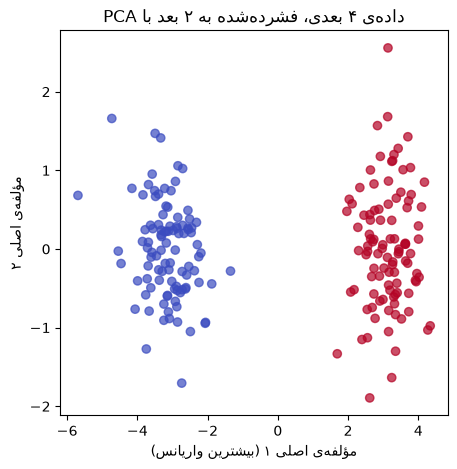

In [4]:
plt.figure(figsize=(5, 5))
plt.scatter(projected[:, 0], projected[:, 1], c=labels, cmap="coolwarm", alpha=0.7)
plt.xlabel("مؤلفه‌ی اصلی ۱ (بیشترین واریانس)")
plt.ylabel("مؤلفه‌ی اصلی ۲")
plt.title("داده‌ی ۴ بعدی، فشرده‌شده به ۲ بعد با PCA")
plt.show()


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### 🗣️ بحث دو‌نفره (Think–Pair–Share) — ۲ دقیقه
دو نمودار بالا (ستون‌های خام در مقابل مؤلفه‌های اصلی PCA) را مقایسه کنید. کدام‌یک دو گروه داده را واضح‌تر از هم جدا نشان می‌دهد؟ چرا فکر می‌کنید این اتفاق افتاده؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



## بخش ۲: PCA از مسیر SVD (اتصال به جلسه ۵)

📘 به‌جای مسیر «ماتریس کوواریانس → بردار ویژه»، می‌توانیم مستقیماً SVD را روی داده‌ی مرکزشده اعمال کنیم — نتیجه دقیقاً همان مؤلفه‌های اصلی است، و در عمل (به‌خصوص برای داده‌های بزرگ) این روش پایدارتر و رایج‌تر است.

In [ ]:
X_centered = data - data.mean(dim=0)
U, S, Vt = torch.linalg.svd(X_centered, full_matrices=False)

# مؤلفه‌های اصلی، همان سطرهای Vt هستند
projected_via_svd = X_centered @ Vt[:2, :].T

# مقایسه با نتیجه‌ی روش قبلی (ممکن است علامت (+/-) بعضی محورها فرق کند، طبیعی است)
print("چند نمونه از نتیجه‌ی روش کوواریانس/بردار ویژه:\n", projected[:3])
print("\nچند نمونه از نتیجه‌ی روش SVD:\n", projected_via_svd[:3])


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




### مقایسه‌ی دو روش روی ماتریسی با مقادیر تکین $1,\ 10^{-5},\ 10^{-9}$

| روش | مقدار تکین دوم | مقدار تکین سوم |
|---|---|---|
| **واقعی** | $9.99\times10^{-6}$ | $9.99\times10^{-10}$ |
| SVD، `float64` | $9.99\times10^{-6}$ ✅ | $9.99\times10^{-10}$ ✅ |
| کوواریانس، `float64` | $9.99\times10^{-6}$ ✅ | مقدار ویژه‌ی $X_c^\top X_c$ **منفی** شد ($-3.4\times10^{-17}$) ❌ |
| SVD، `float32` | $9.99\times10^{-6}$ ✅ | $6.7\times10^{-9}$ (بی‌دقت، ولی هم‌مرتبه) |
| کوواریانس، `float32` | $5.3\times10^{-5}$ (حدود ۵ برابر غلط) ❌ | مقدار ویژه **منفی** شد ($-1.3\times10^{-7}$) ❌ |

📌 در ردیف‌های «کوواریانس»، مقدار تکین را از $\sqrt{\lambda}$ به دست می‌آوریم که $\lambda$ مقدار ویژه‌ی $X_c^\top X_c$ است. وقتی $\lambda$ منفی شود، ریشه‌ی حقیقی ندارد و آن مؤلفه عملاً از دست رفته است.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### چرا SVD از نظر عددی پایدارتر است؟

در مسیر کوواریانس باید ماتریس $X_c^\top X_c$ را بسازیم. این کار **عدد وضعیت (condition number)** را به توان دو می‌رساند:

$$
\kappa(X_c^\top X_c) = \kappa(X_c)^2, \qquad \kappa(X_c) = \frac{\sigma_{\max}}{\sigma_{\min}}
$$

📘 **عدد وضعیت** می‌گوید یک محاسبه چقدر به خطای گردکردن حساس است. کامپیوتر اعداد را با تعداد محدودی رقم نگه می‌دارد (حدود ۱۶ رقم در `float64` و حدود ۷ رقم در `float32`). مقدار ویژه‌ای که در برابر بزرگ‌ترین مقدار ویژه خیلی کوچک باشد، زیر همین خطای گردکردن گم می‌شود.

- روی $X_c^\top X_c$ مقادیر ویژه $\sigma_i^2$ هستند، پس مؤلفه‌ای با $\sigma_i/\sigma_1$ کمتر از حدود $\sqrt{\varepsilon}$ گم می‌شود. در `float64` یعنی نسبت‌های کمتر از حدود $10^{-8}$، و در `float32` کمتر از حدود $3\times10^{-4}$.
- روی خود $X_c$ با SVD، خطا در حدود $\varepsilon\,\sigma_1$ است، پس مؤلفه‌هایی با نسبت‌های خیلی کوچک‌تر هم هنوز دیده می‌شوند.

در سلول بعد، ماتریسی با مقادیر تکین $1,\ 10^{-5},\ 10^{-9}$ می‌سازیم و هر دو روش را در دو دقت اجرا می‌کنیم.

In [5]:
torch.manual_seed(0)
n, d = 200, 3

# ساخت ماتریسی با مقادیر تکین دلخواه: 1, 1e-5, 1e-9
Q1, _ = torch.linalg.qr(torch.randn(n, d, dtype=torch.float64))
Q2, _ = torch.linalg.qr(torch.randn(d, d, dtype=torch.float64))
sigma = torch.tensor([1.0, 1e-5, 1e-9], dtype=torch.float64)
X = Q1 @ torch.diag(sigma) @ Q2.T
X = X - X.mean(dim=0)  # مرکز کردن داده

true_s = torch.linalg.svdvals(X)
print("مقادیر تکین واقعی (تقریباً):", true_s.tolist())
print("σ² واقعی (انتظار از مقادیر ویژه‌ی XᵀX):", (true_s**2).tolist())

for dtype in (torch.float64, torch.float32):
    Xd = X.to(dtype)
    s_svd = torch.linalg.svdvals(Xd)                  # روش SVD
    eig = torch.linalg.eigvalsh(Xd.T @ Xd).flip(0)    # روش کوواریانس (بزرگ به کوچک)
    print(f"\n--- دقت {dtype} ---")
    print("  مقادیر تکین از SVD:          ", s_svd.tolist())
    print("  مقادیر ویژه‌ی XᵀX از eigvalsh:", eig.tolist())

مقادیر تکین واقعی (تقریباً): [0.9999897309605358, 9.964038936816075e-06, 9.996797416846494e-10]
σ² واقعی (انتظار از مقادیر ویژه‌ی XᵀX): [0.9999794620265248, 9.928207193438682e-11, 9.993595859346873e-19]

--- دقت torch.float64 ---
  مقادیر تکین از SVD:           [0.9999897309605358, 9.964038936816075e-06, 9.996797416846494e-10]
  مقادیر ویژه‌ی XᵀX از eigvalsh: [0.999979462026525, 9.928204247069166e-11, -1.531127328827795e-17]

--- دقت torch.float32 ---
  مقادیر تکین از SVD:           [0.9999896287918091, 9.963030606741086e-06, 6.4795817600327155e-09]
  مقادیر ویژه‌ی XᵀX از eigvalsh: [0.9999794960021973, 2.2615610717480195e-08, -3.1038154685303354e-11]


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




### نتیجه را چطور بخوانیم؟

مقادیر ویژه‌ی $X_c^\top X_c$ باید برابر $\sigma_i^2$، یعنی حدود $1,\ 10^{-10},\ 10^{-18}$ باشند. در خروجی بالا:

- **SVD** هر سه مقدار تکین را با دقت خوبی برمی‌گرداند، دست‌کم تا مرتبه‌ی درست. در `float32` مقدار سوم کمی بی‌دقت می‌شود ولی هم‌مرتبه می‌ماند.
- **روش کوواریانس** مقدار ویژه‌ی سوم ($\approx 10^{-18}$) را به‌کلی گم می‌کند. این مقدار زیر خطای گردکردن است و حتی ممکن است **منفی** از آب دربیاید. این جالب است، چون $X_c^\top X_c$ ریاضیاتی نیمه‌معین مثبت است (مقادیر ویژه‌اش $\ge 0$، جلسه‌ی ۴)، ولی خطای گردکردن این خاصیت را در محاسبه می‌شکند. مقادیر تکین طبق تعریف همیشه نامنفی‌اند، پس SVD این مشکل را ندارد.
- در `float32` روش کوواریانس مقدار ویژه‌ی دوم را هم غلط می‌دهد، چون $10^{-10}$ زیر دقت این عددنمایی است.

### دلایل دیگر برای ترجیح SVD

- **حافظه و هزینه وقتی ویژگی‌ها زیادند.** با $d=10000$ ویژگی و $n=100$ نمونه، ماتریس کوواریانس ۱۰۰ میلیون درایه دارد، ولی SVD اقتصادی روی ماتریس $100\times10000$ خیلی ارزان‌تر است.
- **الگوریتم‌های جزئی.** اگر فقط $k$ مؤلفه‌ی اول را بخواهیم، نسخه‌های Truncated و Randomized SVD بدون تجزیه‌ی کامل کار می‌کنند.
- **همه‌چیز یک‌جا.** مؤلفه‌ها ($V$)، تصویر داده ($U\Sigma$) و واریانس هر مؤلفه ($\sigma_i^2/(n-1)$) مستقیم از SVD می‌آیند.

### یک احتیاط

«همیشه SVD» هم درست نیست. اگر $n \gg d$ باشد (مثلاً میلیون‌ها نمونه و ۱۰ ویژگی) و فقط مؤلفه‌های بزرگ مهم باشند، ساختن کوواریانس $d\times d$ سریع‌تر است و دقتش معمولاً کافی است. بعضی کتابخانه‌ها خودکار بین دو روش انتخاب می‌کنند. خلاصه: SVD وقتی داده بدحالت است (ستون‌های تقریباً وابسته، مقیاس‌های خیلی متفاوت) یا ویژگی‌ها زیادند، انتخاب مطمئن‌تری است.

## بخش ۳: کارگاه عملی — روی داده‌ی پروژه‌ی خودتان

اگر داده‌ی پروژه‌ی شما حداقل ۳ ویژگی عددی دارد (واقعی یا فرضی، فعلاً مهم نیست)، آن را به یک ماتریس (نمونه × ویژگی) تبدیل کنید، تابع `pca` بالا را روی آن اجرا کنید، و نتیجه را در ۲ بعد رسم کنید. یک جمله بنویسید: آیا الگویی (خوشه، روند) در نمودار می‌بینید که با شهودتان از داده هم‌خوانی دارد؟

In [ ]:
# فضای کار تیم شما 👇
my_data = torch.tensor([[...]])  # TODO: چند سطر (نمونه) × چند ستون (ویژگی)

projected, evr = pca(my_data, n_components=2)
print("واریانس حفظ‌شده:", evr.tolist())

plt.scatter(projected[:, 0], projected[:, 1])
plt.title("داده‌ی پروژه‌ی شما در ۲ بعد")
plt.show()


Variance retained: [0.2845887391375508, 0.18201735427537152]


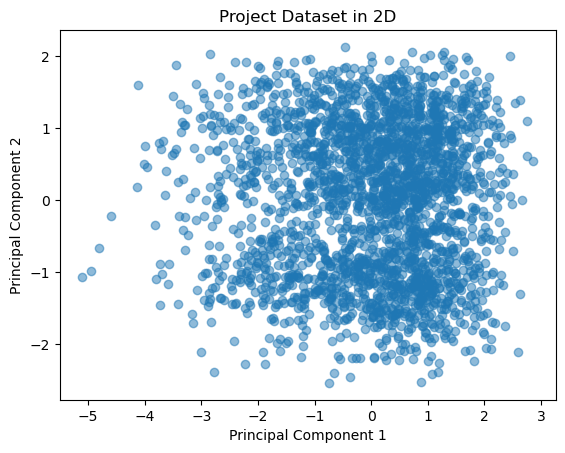

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_excel("Dataset.xlsx", sheet_name="design_matrix")

# Select numerical features
features = [
    "own_price",
    "competitor_min_price",
    "competitor_mean_price",
    "own_seller_rating",
    "competitor_mean_rating",
    "customer_arrivals_in_interval"
]

# Convert to sample × feature matrix
my_data = df[features].to_numpy()

# Standardize the features
my_data = (my_data - my_data.mean(axis=0)) / my_data.std(axis=0)

# Apply the provided PCA function
projected, evr = pca(my_data, n_components=2)

print("Variance retained:", evr.tolist())

# Plot in 2D
plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Project Dataset in 2D")
plt.show()


The data is clamped together, which makes sense, as features are very close together (many of them are ordinal and are between 1 and 5 and the numerical vlaues are very close).

## جمع‌بندی و تکلیف

**تکلیف قبل از جلسه‌ی بعد:**
1. کارگاه این جلسه را با داده‌ی واقعی یا فرضی پروژه‌تان کامل کنید.
2. یک مرور سریع بر مفهوم مشتق و گرادیان (اگر یادتان رفته) داشته باشید — جلسه‌ی بعد از همین‌جا شروع می‌شود.

**منابع این جلسه:**
- Deisenroth et al. — *Mathematics for Machine Learning*, فصل ۱۰ (Dimensionality Reduction with PCA)
- Zhang et al. — *Dive into Deep Learning*, بخش‌های مرتبط با پیش‌پردازش داده
- Strang — *Linear Algebra and Learning from Data*, فصل ۷ (PCA)


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


## 📐 عدد وضعیت (Condition Number)

### ۱) تعریف کلی: عدد وضعیت یک «مسئله»

فرض کنید مسئله‌ی ما محاسبه‌ی $y = f(x)$ است. **عدد وضعیت نسبی** مسئله در نقطه‌ی $x$ این است:

$$
\kappa_f(x) \;=\; \lim_{\delta\to 0}\ \sup_{\|\delta x\|\le \delta\|x\|}\ 
\frac{\|f(x+\delta x)-f(x)\| \,/\, \|f(x)\|}{\|\delta x\| \,/\, \|x\|}
$$

یعنی ورودی را به‌اندازه‌ی کوچکی (نسبی) تغییر می‌دهیم و **بدترین حالت** نسبت «تغییر نسبی خروجی» به «تغییر نسبی ورودی» را می‌گیریم. اگر $f$ مشتق‌پذیر باشد و $J$ ماتریس ژاکوبین آن (جلسه‌ی ۸) باشد:

پس عدد وضعیت همان **ضریب تقویت خطای نسبی** در بدترین حالت است.

### ۲) عدد وضعیت یک ماتریس

برای حل دستگاه $Ax=b$ با $A$ وارون‌پذیر، عدد وضعیت ماتریس تعریف می‌شود:

$$
\kappa(A) = \|A\|\,\|A^{-1}\|
$$

برای نرم طیفی ($\|\cdot\|_2$) این به **مقادیر تکین** (جلسه‌ی ۵) تبدیل می‌شود:

$$
\kappa_2(A) = \frac{\sigma_{\max}(A)}{\sigma_{\min}(A)}
$$

- برای ماتریس غیرمربعی با ستون‌های مستقل، $\sigma_{\min}$ کوچک‌ترین مقدار تکین ناصفر است (معادلاً $\kappa=\|A\|\,\|A^+\|$ با شبه‌وارون).
- اگر رتبه‌ی ماتریس کامل نباشد، $\kappa=\infty$ قرار می‌دهیم.
- برای ماتریس متقارن معین مثبت (مثل هسین یا کوواریانس): $\kappa_2 = \lambda_{\max}/\lambda_{\min}$.


## تفسیر

**تفسیر هندسی.** ماتریس $A$ دایره‌ی (کره‌ی) واحد را به یک بیضی (بیضوی) با نیم‌محورهای $\sigma_1\ge\cdots\ge\sigma_n$ می‌برد (جلسه‌ی ۵). $\kappa$ نسبت بلندترین محور به کوتاه‌ترین محور است، یعنی میزان «کشیدگی» بیضی. $\kappa=1$ یعنی دایره، و $\kappa$ بزرگ یعنی بیضی خیلی باریک.

**تفسیر حساسیت.** خطا در جهت‌های مربوط به $\sigma_{\min}$ در حل $Ax=b$ تقریباً $1/\sigma_{\min}$ برابر تقویت می‌شود، در حالی که در جهت $\sigma_{\max}$ فقط $1/\sigma_{\max}$ برابر. $\kappa$ نسبت بدترین به بهترین حالت است.

**تفسیر عددی (قاعده‌ی سرانگشتی).** در محاسبه با دقت ماشین $\varepsilon$ (حدود $10^{-16}$ برای `float64` و $10^{-7}$ برای `float32`)، خطای نسبی جواب تقریباً از مرتبه‌ی $\kappa\cdot\varepsilon$ است. یعنی **حدود $\log_{10}\kappa$ رقم دقت از دست می‌رود**. اگر $\kappa\approx 1/\varepsilon$ باشد، ممکن است هیچ رقم درستی نماند.

**تفسیر در بهینه‌سازی.** برای تابع $\tfrac12 x^\top H x$ با $\kappa=\lambda_{\max}/\lambda_{\min}$ و نزول گرادیان با گام بهینه $2/(\lambda_{\max}+\lambda_{\min})$، خطا در هر قدم حداکثر در $\frac{\kappa-1}{\kappa+1}$ ضرب می‌شود. برای $\kappa=10$ این ضریب $0.818$ است و برای $\kappa=1000$ حدود $0.998$، یعنی همگرایی بسیار کند. این همان «دره‌ی کشیده‌ی» جلسه‌ی ۹ است.

###  یک مثال عددی

$$
A=\begin{bmatrix}1&1\\1&1.0001\end{bmatrix},\qquad b=\begin{bmatrix}2\\2.0001\end{bmatrix}\ \Rightarrow\ x=\begin{bmatrix}1\\1\end{bmatrix}
$$

مقادیر تکین $A$ حدود $2$ و $5\times10^{-5}$ است، پس $\kappa\approx 4\times10^4$. حالا $b$ را فقط در رقم چهارم اعشار تغییر می‌دهیم: $b' = (2,\ 2.0002)$. جواب می‌شود $x'=(0,\ 2)$.

| کمیت | مقدار |
|---|---|
| تغییر نسبی $b$ | حدود $3.5\times10^{-5}$ |
| تغییر نسبی $x$ | حدود $1$ (یعنی ۱۰۰٪!) |
| ضریب تقویت | حدود $2.8\times10^4$ |

ضریب تقویت از کران $\kappa\approx4\times10^4$ کمتر است ولی به آن نزدیک است.

